# ResNet-18 + pretrained vowel recognition

No training. Your ResNet predicts bases; a frozen external head predicts vowel signs.
Use your existing `.venv`. Install `requirements-hybrid.txt` if needed.


## 1. Setup


In [1]:
# Select Python Work (.venv) as the notebook kernel.
import os
import sys
from pathlib import Path

os.environ['KERAS_BACKEND'] = 'torch'  # Set this before importing Keras.

import json
import time
from html import escape

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import HTML, display
from PIL import Image

print('Python:', sys.executable)
torch.set_num_threads(2)  # Predictable CPU use on the Mac; this does not train anything.


Python: /Users/sakibsmacbookm5/Documents/Python work/.venv/bin/python


In [2]:
PROJECT_DIR = Path.cwd().resolve()
CHECKPOINT = PROJECT_DIR / 'training_runs/macos_resnet18_efficientnetb0_v1/character/resnet18/best_model.pt'
HELPER_DIR = PROJECT_DIR / 'models/vowel_helper'
REPORT_DIR = PROJECT_DIR / 'reports/hybrid_word_recognition'

# Later, change only this path and rerun the custom-prediction cell.
IMAGE_PATH = None  # Example: PROJECT_DIR / 'my_manush_drawing.png'
TEST_CSV = None    # Independent test drawings: UTF-8 CSV with path,expected columns.

assert (PROJECT_DIR / 'hybrid_ocr.py').is_file(), 'Open this notebook from the project folder.'
assert CHECKPOINT.is_file(), 'Update CHECKPOINT to your saved ResNet-18.'
REPORT_DIR.mkdir(parents=True, exist_ok=True)


In [3]:
from hybrid_ocr import (
    file_sha256, prepare_vowel_helper, load_hybrid_engine,
    predict_word, vowel_probabilities, grapheme_regions,
)
from hybrid_evaluation import evaluate_words, save_prediction, cached_prediction, SIGN_NAMES
import segmentation_ocr as base_ocr

# Pinned files are checked by SHA-256. The first run downloads about 43 MB.
# If the files already exist, this works without an internet connection.
helper_dir = prepare_vowel_helper(HELPER_DIR, download=True)

checkpoint_hash_before = file_sha256(CHECKPOINT)
print('Helper ready:', helper_dir)


Helper ready: /Users/sakibsmacbookm5/Documents/Python work/research-project/SICIP - Assignment 4/models/vowel_helper


## 2. Load both frozen models


In [4]:
started = time.perf_counter()
engine = load_hybrid_engine(CHECKPOINT, helper_dir=helper_dir)
PREDICTION_CACHE = {}  # Reuse unchanged images across notebook cells.

print('Load time:', round(time.perf_counter() - started, 2), 'seconds')
print('Base model: your trained ResNet-18, 84 classes')
print('Helper output:', engine['vowel_head'].output_shape, '(vowel classes only)')
print('Trainable helper variables:', len(engine['vowel_head'].trainable_variables))
print('Root model in training mode:', engine['resnet']['model'].training)
print('Settings:', engine['settings'])

display(pd.DataFrame([
    {'helper_class': key, 'vowel_sign': value or '(none)'}
    for key, value in engine['vowel_labels'].items()
]))


Load time: 2.2 seconds
Base model: your trained ResNet-18, 84 classes
Helper output: (None, 11) (vowel classes only)
Trainable helper variables: 0
Root model in training mode: False
Settings: {'max_width': 1100, 'max_atoms': 20, 'max_span': 3, 'max_regions': 128, 'beam_width': 10, 'top_k': 3, 'min_base_score': 0.5, 'min_vowel_score': 0.5, 'min_path_margin': 0.08, 'batch_size': 4, 'vowel_tta': False, 'min_sign_hypothesis': 0.85}


,helper_class,vowel_sign
0,0,(none)
1,1,া
2,2,ি
3,3,ী
4,4,ু
5,5,ূ
6,6,ৃ
7,7,ে
8,8,ৈ
9,9,ো


## 3. Show the joined word and the model evidence

Red boxes contain whole graphemes; cyan boxes are the crops sent to your ResNet.
Scores are uncalibrated. “Uncertain” means inspect the alternatives or redraw.


In [5]:
def show_word(result):
    label = 'Predicted word' if result['status'] == 'accepted' else 'Candidate word'
    display(HTML(f'<h3>{label}: {escape(result["word"])}</h3>'))
    print('Status:', result['status'], '| time:', round(result['latency_ms']), 'ms')

    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    images = [result['debug']['gray'], result['debug']['body_mask'], result['debug']['gray']]
    titles = ['Word input', 'Mask used to propose cuts', 'Red: graphemes / cyan: ResNet crops']

    for ax, pixels, title in zip(axes, images, titles):
        ax.imshow(pixels, cmap='gray')
        ax.set_title(title)
        ax.axis('off')

    for index, token in enumerate(result['tokens'], 1):
        for key, color in [('box', 'red'), ('base_box', 'cyan')]:
            left, top, right, bottom = token[key]
            axes[2].add_patch(plt.Rectangle((left, top), right-left, bottom-top,
                                           fill=False, color=color, linewidth=1.5))
        axes[2].text(token['box'][0], 0, str(index), color='red')

    fig.tight_layout()
    plt.show()
    return fig


In [6]:
def show_evidence(result):
    rows = [{
        'base_from_your_ResNet': token['base'],
        'your_class_id': token['base_class_id'],
        'helper_vowel': token['vowel'] or '(none)',
        'base_score': round(token['base_probability'], 3),
        'vowel_score': round(token['vowel_probability'], 3),
        'base_crop': token['view'],
    } for token in result['tokens']]

    display(pd.DataFrame(rows))
    display(pd.DataFrame([
        {'word': path['word'], 'score': round(path['score'], 3),
         'evidence_ok': path['meets_evidence_thresholds'], 'cuts': path['method']}
        for path in result['alternatives']
    ]))

    for warning in result['warnings']:
        print('Note:', warning)


In [7]:
def inspect_word(path, name='custom_word'):
    result = cached_prediction(engine, path, PREDICTION_CACHE)  # No expected text is supplied.
    figure = show_word(result)
    figure.savefig(REPORT_DIR / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.close(figure)

    show_evidence(result)
    save_prediction(result, REPORT_DIR / f'{name}.json')
    return result


## 4. Run the same real examples, including failures


Image: 0.bmp


Status: uncertain | time: 4384 ms


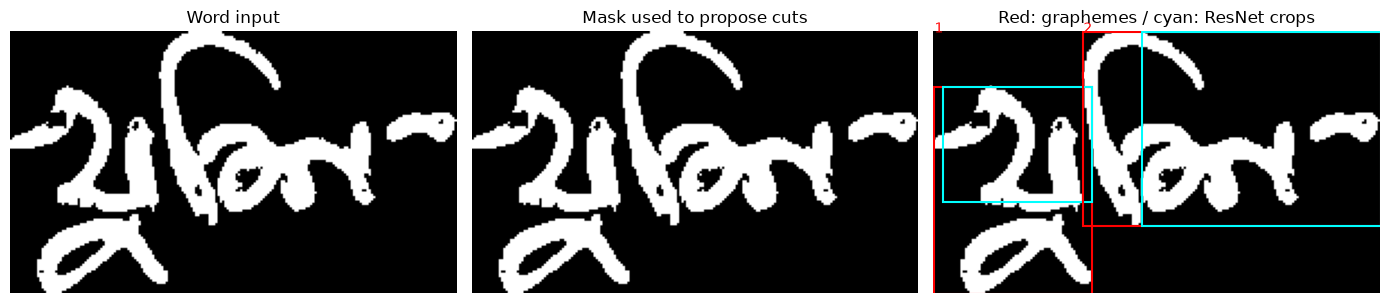

,base_from_your_ResNet,your_class_id,helper_vowel,base_score,vowel_score,base_crop
0,খ,13,ু,0.846,0.999,word-baseline crop + boundary refinement
1,শ,40,ি,0.932,1.000,sign-aware crop


,word,score,evidence_ok,cuts
0,খুশি,-0.386,True,components
1,থুশি,-0.405,True,touching-valley
2,স্নুশি,-0.518,True,components
3,খুমি,-1.176,False,components
4,ফুশি,-1.192,False,components


Note: Scores are uncalibrated; a confident prediction may still be wrong.
Note: Several different joined words have similar scores.
Image: 1177.bmp


Status: accepted | time: 1224 ms


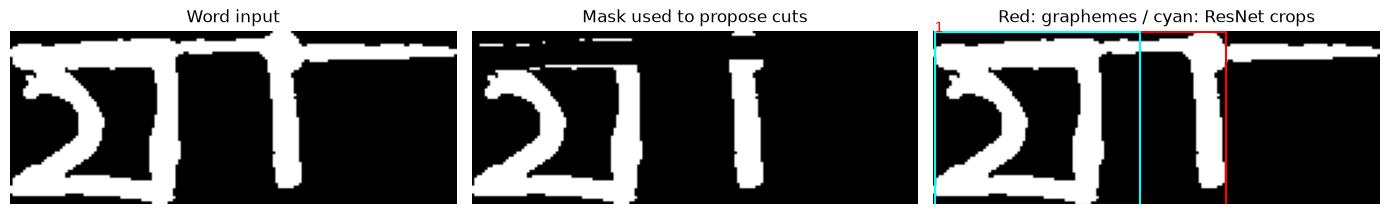

,base_from_your_ResNet,your_class_id,helper_vowel,base_score,vowel_score,base_crop
0,য,37,া,0.954,0.999,sign-aware crop


,word,score,evidence_ok,cuts
0,যা,-0.244,True,adaptive-matra
1,ফা,-0.825,False,components
2,যার,-1.578,False,matra-components
3,যাব্দ,-1.644,False,matra-components
4,যাব্দর,-2.290,False,matra-components


Note: Scores are uncalibrated; a confident prediction may still be wrong.
Image: 1100.bmp


Status: accepted | time: 1301 ms


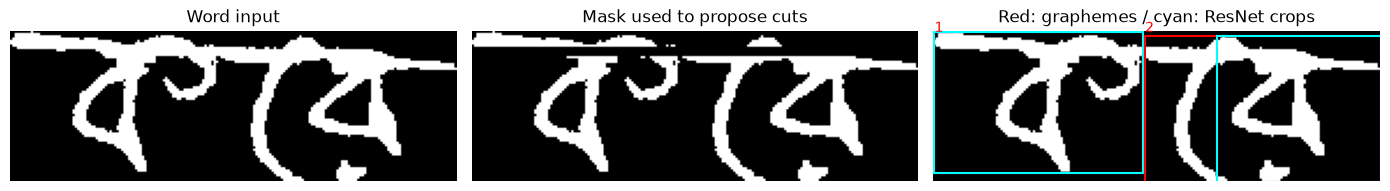

,base_from_your_ResNet,your_class_id,helper_vowel,base_score,vowel_score,base_crop
0,ক,12,(none),0.953,0.996,full
1,র,38,ে,0.956,0.998,sign-aware crop


,word,score,evidence_ok,cuts
0,করে,-0.268,True,matra-components
1,ব০রে,-0.485,True,touching-valley
2,কার,-0.537,True,touching-valley
3,বর০রে,-0.544,True,adaptive-matra
4,বরে,-0.553,True,touching-valley


Note: Scores are uncalibrated; a confident prediction may still be wrong.
Image: 10.bmp


Status: accepted | time: 931 ms


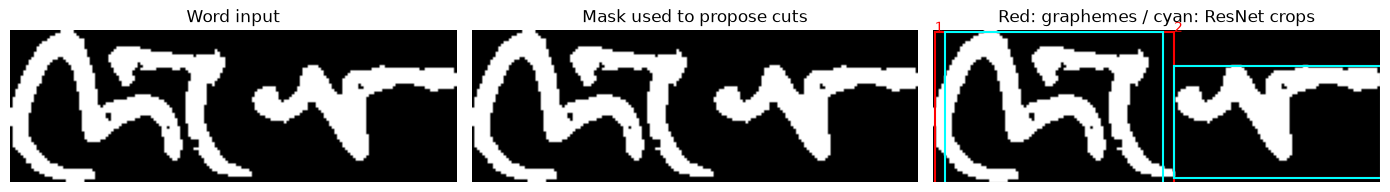

,base_from_your_ResNet,your_class_id,helper_vowel,base_score,vowel_score,base_crop
0,জ,19,ো,0.638,0.905,sign-aware crop
1,ণ,26,(none),0.858,0.980,full


,word,score,evidence_ok,cuts
0,জোণ,-0.938,True,touching-valley
1,জোব্দণ,-1.414,True,adaptive-matra
2,সোণ,-1.343,False,touching-valley
3,ণপ,-1.574,False,middle-zone
4,ণদণ,-1.752,False,middle-zone


Note: Scores are uncalibrated; a confident prediction may still be wrong.


,image,word,status
0,0.bmp,খুশি,uncertain
1,1177.bmp,যা,accepted
2,1100.bmp,করে,accepted
3,10.bmp,জোণ,accepted


In [8]:
promito = (
    PROJECT_DIR / 'Handwritten word' /
    'PromitoLipi A versatile offline dataset of handwritten Bangla words and paragraphs' /
    'PromitoLipi' / 'PromitoLipi2.1' / 'Word Images(bmp)'
)

demo_results = []

for name in ['0', '1177', '1100', '10']:
    path = promito / f'{name}.bmp'
    if path.is_file():
        print('Image:', path.name)
        result = inspect_word(path, f'promito_{name}')
        demo_results.append({'image': path.name, 'word': result['word'], 'status': result['status']})

if demo_results:
    display(pd.DataFrame(demo_results))
else:
    print('Optional PromitoLipi examples are absent; use your drawing below.')


In [9]:
# Set IMAGE_PATH in section 1, then rerun this cell for each new drawing.
# Draw the entire word, including its vowel signs, in one image.
if IMAGE_PATH is not None:
    try:
        custom_result = inspect_word(IMAGE_PATH)
    except (OSError, ValueError) as problem:
        print('Cannot read this input:', problem)
else:
    print('Set IMAGE_PATH to test a new drawing of মানুষ, জল, or another word.')


Set IMAGE_PATH to test a new drawing of মানুষ, জল, or another word.


## 5. Inspect the learned vowel decisions

Each row is a proposed full grapheme. Competing cuts can overlap.


In [10]:
preview_path = IMAGE_PATH or (promito / '0.bmp')

if Path(preview_path).is_file():
    preview = cached_prediction(engine, preview_path, PREDICTION_CACHE)
    regions = preview['debug']['regions']
    probabilities = preview['debug']['vowel_scores']

    preview_rows = []
    for region, scores in zip(regions, probabilities):
        choices = scores.argsort()[-3:][::-1]
        preview_rows.append({
            'box': region['box'],
            'cuts': region['method'],
            'vowel_candidates': [engine['vowel_labels'][int(i)] or '(none)' for i in choices],
            'scores': [round(float(scores[i]), 3) for i in choices],
        })

    display(pd.DataFrame(preview_rows))


,box,cuts,vowel_candidates,scores
0,"[0, 24, 70, 116]",components,"[ু, (none), ূ]","[0.999, 0.0, 0.0]"
1,"[0, 0, 162, 116]",components,"[ু, া, ি]","[0.698, 0.255, 0.014]"
2,"[0, 0, 198, 116]",components,"[ু, া, ি]","[0.744, 0.183, 0.025]"
3,"[66, 0, 162, 86]",components,"[ি, ৈ, ো]","[1.0, 0.0, 0.0]"
4,"[66, 0, 198, 86]",components,"[ি, ৈ, া]","[1.0, 0.0, 0.0]"
5,"[167, 36, 198, 49]",components,"[(none), া, ু]","[0.837, 0.159, 0.002]"
6,"[0, 0, 162, 116]",vertical-projection,"[ু, া, ি]","[0.698, 0.255, 0.014]"
7,"[0, 0, 198, 116]",vertical-projection,"[ু, া, ি]","[0.744, 0.183, 0.025]"
8,"[167, 36, 198, 49]",vertical-projection,"[(none), া, ু]","[0.837, 0.159, 0.002]"
9,"[0, 24, 66, 116]",touching-valley,"[ু, (none), ূ]","[0.999, 0.0, 0.0]"


## 6. Development comparison

These six examples were inspected during implementation: **not a held-out benchmark**.
The CSV contains visual transcriptions for review. All failures and rejections are counted.


In [11]:
development_csv = PROJECT_DIR / 'examples/hybrid_development_words.csv'
development_labels = pd.read_csv(development_csv, keep_default_na=False)
development_available = all(
    (development_csv.parent / path).is_file() for path in development_labels['path']
)

if development_available:
    words, vowels, development_summary = evaluate_words(
        engine, development_csv, REPORT_DIR / 'development', evaluation_kind='development_only', prediction_cache=PREDICTION_CACHE,
    )
    display(words[['expected', 'prediction', 'status', 'baseline_prediction', 'raw_correct']])
    display(pd.DataFrame([development_summary]))
else:
    print('Optional local word images are absent; supply your own labeled evaluation CSV.')


,expected,prediction,status,baseline_prediction,raw_correct
0,খুশি,খুশি,uncertain,স্নশ�,True
1,এক,এক,accepted,এক,True
2,যা,যা,accepted,য�ব্দব্দ�ব্দার,True
3,করে,করে,accepted,ব০�র,True
4,দেশ,জোণ,accepted,জণ,False
5,আ,আ,accepted,আ,True


,evaluation_kind,examples,raw_word_accuracy,accepted_word_accuracy_rejections_as_errors,acceptance_rate,baseline_word_accuracy,codepoint_cer,aligned_vowel_error_rate,median_latency_ms,p95_latency_ms,training_performed
0,development_only,6,0.833333,0.666667,0.833333,0.333333,0.2,0.1,1077.172583,3613.489968,False


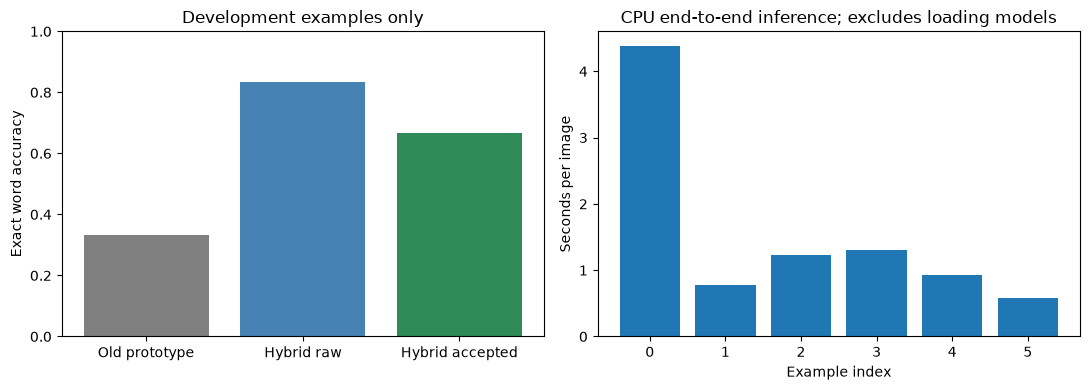

In [12]:
if development_available:
    labels = ['Old prototype', 'Hybrid raw', 'Hybrid accepted']
    values = [development_summary['baseline_word_accuracy'],
              development_summary['raw_word_accuracy'],
              development_summary['accepted_word_accuracy_rejections_as_errors']]

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].bar(labels, values, color=['gray', 'steelblue', 'seagreen'])
    axes[0].set_ylim(0, 1)
    axes[0].set_ylabel('Exact word accuracy')
    axes[0].set_title('Development examples only')
    axes[1].bar(range(len(words)), words['latency_ms'] / 1000)
    axes[1].set_xlabel('Example index')
    axes[1].set_ylabel('Seconds per image')
    axes[1].set_title('CPU end-to-end inference; excludes loading models')
    fig.tight_layout()
    fig.savefig(REPORT_DIR / 'development_comparison.png', dpi=150)
    plt.show()
    plt.close(fig)


In [13]:
# Precision/recall here describe aligned vowel decisions on DEVELOPMENT images.
# Base-letter errors are recorded separately; correct vowel signs do not imply correct words.
if development_available:
    vowel_report = []
    for sign, name in SIGN_NAMES.items():
        truth = vowels['expected_sign'].eq(sign)
        guess = vowels['predicted_sign'].eq(sign)
        tp = int((truth & guess).sum())
        precision = tp / guess.sum() if guess.sum() else float('nan')
        recall = tp / truth.sum() if truth.sum() else float('nan')
        vowel_report.append({'vowel': sign or '(none)', 'name': name,
                             'support': int(truth.sum()), 'precision': precision, 'recall': recall})

    vowel_report = pd.DataFrame(vowel_report)
    display(vowel_report)
    vowel_report.to_csv(REPORT_DIR / 'development/vowel_report.csv', index=False)


,vowel,name,support,precision,recall
0,(none),none,5,1.0,1.0
1,া,aa,1,1.0,1.0
2,ি,i,1,1.0,1.0
3,ী,ii,0,NaN,NaN
4,ু,u,1,1.0,1.0
5,ূ,uu,0,NaN,NaN
6,ৃ,ri,0,NaN,NaN
7,ে,e,2,1.0,0.5
8,ৈ,ai,0,NaN,NaN
9,ো,o,0,0.0,NaN


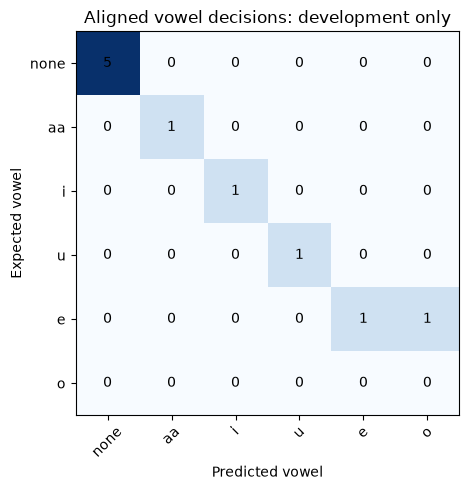

In [14]:
if development_available:
    truth = vowels['expected_sign'].map(lambda s: SIGN_NAMES.get(s, 'missing/other'))
    guess = vowels['predicted_sign'].map(lambda s: SIGN_NAMES.get(s, 'missing/other'))
    classes = [name for name in SIGN_NAMES.values() if name in set(truth) | set(guess)]
    classes += ['missing/other'] if 'missing/other' in set(truth) | set(guess) else []
    matrix = pd.crosstab(truth, guess).reindex(index=classes, columns=classes, fill_value=0)

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.imshow(matrix, cmap='Blues')
    ax.set_xticks(range(len(classes)), classes, rotation=45)
    ax.set_yticks(range(len(classes)), classes)
    ax.set_xlabel('Predicted vowel')
    ax.set_ylabel('Expected vowel')
    ax.set_title('Aligned vowel decisions: development only')
    for i in range(len(classes)):
        for j in range(len(classes)):
            ax.text(j, i, str(matrix.iloc[i, j]), ha='center', va='center')
    fig.tight_layout()
    fig.savefig(REPORT_DIR / 'development_vowel_confusion.png', dpi=150)
    plt.show()
    plt.close(fig)


## 7. Target-word diagnostics: include every failure

These natural মানুষ samples were used to debug segmentation; they are not held out.
The জল examples below are word crops from handwritten গজল, not new independent drawings.


In [15]:
target_csv = PROJECT_DIR / 'examples/hybrid_manush_diagnostics.csv'
target_labels = pd.read_csv(target_csv, keep_default_na=False)
target_available = all((target_csv.parent / path).is_file() for path in target_labels['path'])

if target_available:
    target_words, target_vowels, target_summary = evaluate_words(
        engine, target_csv, REPORT_DIR / 'manush_diagnostics',
        evaluation_kind='target_development_not_heldout', prediction_cache=PREDICTION_CACHE,
    )
    display(target_words[['expected', 'prediction', 'status', 'raw_correct']])
    print('Correct natural মানুষ examples:', int(target_words['raw_correct'].sum()), '/', len(target_words))
    print('These results do not establish accuracy on your new drawings.')


,expected,prediction,status,raw_correct
0,মানুষ,মানুষ,accepted,True
1,মানুষ,ম্মা,accepted,False
2,মানুষ,মষি,accepted,False
3,মানুষ,মাষে,accepted,False


Correct natural মানুষ examples: 1 / 4
These results do not establish accuracy on your new drawings.


Status: accepted | time: 442 ms


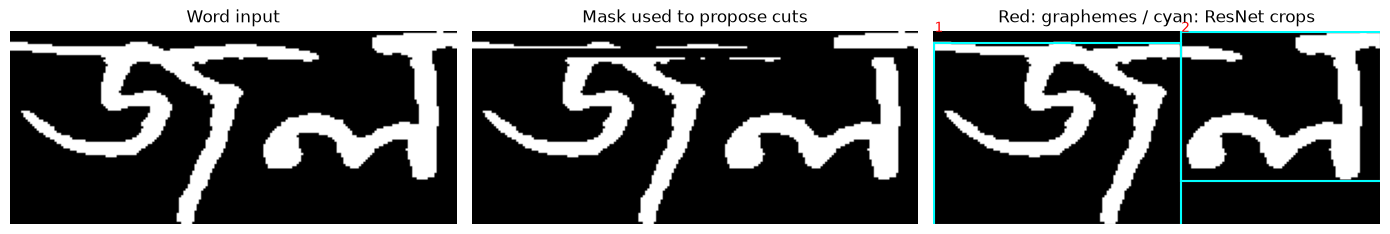

,base_from_your_ResNet,your_class_id,helper_vowel,base_score,vowel_score,base_crop
0,জ,19,(none),0.942,0.953,full
1,ল,39,(none),0.969,0.998,full


,word,score,evidence_ok,cuts
0,জল,-0.209,True,touching-valley
1,ডলি,-0.332,True,adaptive-matra
2,ডণল,-0.707,False,adaptive-matra
3,ংগল,-0.844,False,middle-zone
4,ডপল,-1.009,False,adaptive-matra


Note: Scores are uncalibrated; a confident prediction may still be wrong.


Status: accepted | time: 386 ms


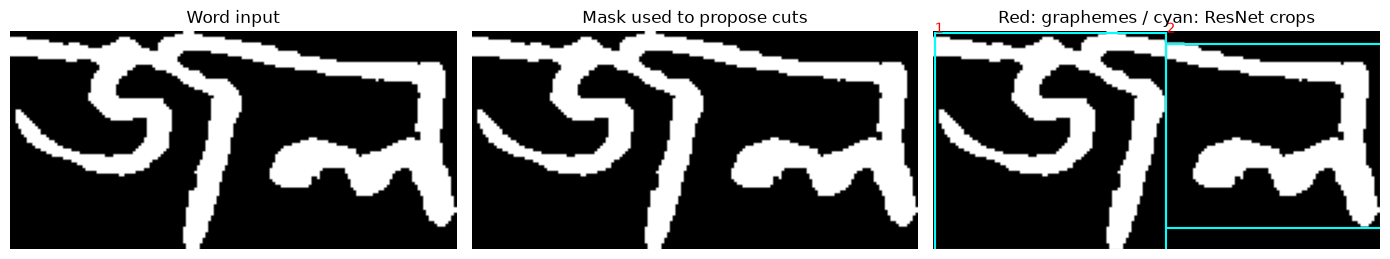

,base_from_your_ResNet,your_class_id,helper_vowel,base_score,vowel_score,base_crop
0,জ,19,(none),0.951,0.952,full
1,ল,39,(none),0.951,0.999,full


,word,score,evidence_ok,cuts
0,জল,-0.075,True,touching-valley
1,ডলি,-0.507,True,adaptive-matra
2,ল,-1.125,False,components
3,জ,-1.829,False,components
4,জলি,-1.913,False,adaptive-matra


Note: Scores are uncalibrated; a confident prediction may still be wrong.


,source,expected,prediction,status,input_kind
0,20052,জল,জল,accepted,crop from গজল; not an independent test drawing
1,20588,জল,জল,accepted,crop from গজল; not an independent test drawing


In [16]:
# Fixed word-level crops: no character boundaries are supplied to predict_word().
# Crop coordinates come from the source annotations and were visually reviewed.
jol_crops = [('20052', (134, 28, 335, 137)), ('20588', (112, 60, 283, 161))]
derived_results = []

for source_name, rectangle in jol_crops:
    original = promito / f'{source_name}.bmp'
    if original.is_file():
        crop_path = REPORT_DIR / f'jol_crop_{source_name}.png'
        with Image.open(original) as image:
            image.crop(rectangle).save(crop_path)

        result = inspect_word(crop_path, f'jol_crop_{source_name}')
        derived_results.append({'source': source_name, 'expected': 'জল',
                                'prediction': result['word'], 'status': result['status'],
                                'input_kind': 'crop from গজল; not an independent test drawing'})

if derived_results:
    display(pd.DataFrame(derived_results))
    (REPORT_DIR / 'derived_jol_results.json').write_text(
        json.dumps(derived_results, ensure_ascii=False, indent=2), encoding='utf-8',
    )


## 8. Your independent test drawings

Set `TEST_CSV` in section 1. Relative paths resolve from the CSV folder.
See `examples/hybrid_test.example.csv`. Include repeated মানুষ/জল drawings and all vowel signs.


In [17]:
if TEST_CSV is not None:
    test_words, test_vowels, test_summary = evaluate_words(
        engine, TEST_CSV, REPORT_DIR / 'independent_test',
        evaluation_kind='user_supplied_test_not_used_for_rule_tuning',
    )
    display(test_words)
    display(pd.DataFrame([test_summary]))
else:
    print('Independent accuracy on your new মানুষ/জল drawings remains unverified.')


Independent accuracy on your new মানুষ/জল drawings remains unverified.


## 9. Confirm no training or checkpoint changes


In [18]:
assert file_sha256(CHECKPOINT) == checkpoint_hash_before
assert not engine['resnet']['model'].training
assert all(not p.requires_grad and p.grad is None for p in engine['resnet']['model'].parameters())
assert len(engine['vowel_head'].trainable_variables) == 0
assert engine['provenance']['helper_root_output_used'] is False

print('Your checkpoint is unchanged. Both models are frozen.')
print('Every base token is from your ResNet; the external model supplies vowel scores only.')
print('Reports:', REPORT_DIR)


Your checkpoint is unchanged. Both models are frozen.
Every base token is from your ResNet; the external model supplies vowel scores only.
Reports: /Users/sakibsmacbookm5/Documents/Python work/research-project/SICIP - Assignment 4/reports/hybrid_word_recognition


Sources: `vowel_helper_sources.json`. The helper was trained by its author on Bengali.AI;
your model was trained on BanglaLekha. The helper does not expand your 84 base classes.
Unsupported conjuncts and different writing styles can still fail, sometimes confidently.


## 10. Predict 200 real word images

Run this section independently. View each image beside its predicted whole word; no labeling input is needed.
Saved predictions are reused. `uncertain` marks a model warning, not a correctness judgment.


In [16]:
import os
import sys
import json
import subprocess
import base64
from io import BytesIO
from html import escape
from pathlib import Path

os.environ['KERAS_BACKEND'] = 'torch'

import pandas as pd
from PIL import Image
from IPython.display import display, HTML, FileLink
from word_benchmark import prepare_word_sample, score_word_benchmark

PROJECT_DIR = Path.cwd().resolve()
assert (PROJECT_DIR / 'run_200_word_test.py').is_file(), 'Open this notebook from the project folder.'


In [17]:
SOURCE_DATASET = (
    PROJECT_DIR / 'Handwritten word' /
    'PromitoLipi A versatile offline dataset of handwritten Bangla words and paragraphs' /
    'PromitoLipi' / 'PromitoLipi2.1'
)
REFERENCE_200 = PROJECT_DIR / 'examples/promitolipi_200_reference_words.csv'
REPORT_200 = PROJECT_DIR / 'reports/hybrid_word_recognition/test_200_words'
CHECKPOINT_200 = PROJECT_DIR / 'training_runs/macos_resnet18_efficientnetb0_v1/character/resnet18/best_model.pt'

RUN_200_INFERENCE = True  # Reuses cached predictions; resumes unfinished images.
BENCHMARK_SETTINGS = {}

sample_200 = prepare_word_sample(SOURCE_DATASET, REFERENCE_200, count=200)
assert CHECKPOINT_200.is_file(), 'Saved ResNet checkpoint not found.'
REPORT_200.mkdir(parents=True, exist_ok=True)
print('Real word images:', len(sample_200))
print('Base model:', CHECKPOINT_200.name, '(your trained ResNet-18)')


Real word images: 200
Base model: best_model.pt (your trained ResNet-18)


In [18]:
# Run your saved ResNet plus the frozen vowel helper. No training or label input.
# Each finished image is saved, so interrupted inference can resume.
if RUN_200_INFERENCE:
    command = [
        sys.executable, str(PROJECT_DIR / 'run_200_word_test.py'),
        '--labels', str(REFERENCE_200), '--output', str(REPORT_200),
        '--checkpoint', str(CHECKPOINT_200),
        '--settings-json', json.dumps(BENCHMARK_SETTINGS),
    ]
    subprocess.run(command, cwd=PROJECT_DIR, check=True)
else:
    print('Reading saved predictions only.')


{"total_images": 200, "labeled_images": 2, "verified_reference_images": 2, "accuracy_status": "awaiting_verified_references", "correct_predictions": null, "incorrect_predictions": null, "exact_word_accuracy": null, "accepted_word_accuracy_rejections_as_errors": null, "inference_errors": 0, "uncertain_predictions": 56, "accepted_predictions": 144, "median_latency_ms": 5455.312666512327, "p95_latency_ms": 14067.819196449997, "accuracy_definition": "NFC-normalized whole-word exact matches / all 200 images; no character averaging or accepted-only denominator."}
Saved 200/200 predictions.


In [19]:
# Join image paths with saved model outputs. Reference words are not needed.
prediction_file = REPORT_200 / 'predictions.csv'
assert prediction_file.is_file(), 'Run the inference cell first.'

predictions_200 = pd.read_csv(prediction_file, dtype=str, keep_default_na=False)
images_200 = pd.read_csv(REFERENCE_200, dtype=str, keep_default_na=False)
word_images_200 = images_200[['test_id', 'path']].merge(
    predictions_200.drop(columns='path'), on='test_id', validate='one_to_one'
)
assert len(word_images_200) == len(predictions_200), 'Prediction IDs do not match the image list.'

print(f'Saved predictions: {len(word_images_200)}/200')
display(word_images_200[['test_id', 'prediction', 'status']].set_index('test_id'))


Saved predictions: 200/200


,prediction,status
test_id,,
1,ওৎ,accepted
2,রে,uncertain
3,করে,accepted
4,রে,accepted
5,ষঢ়ক্ত,accepted
...,...,...
196,স্ফ,accepted
197,ঈদ,accepted
198,ভয়ে৪,uncertain


In [20]:
def prediction_card(row):
    image_path = REFERENCE_200.parent / row.path
    with Image.open(image_path) as image:
        buffer = BytesIO()
        image.convert('RGB').save(buffer, format='PNG')
    encoded = base64.b64encode(buffer.getvalue()).decode('ascii')

    word = escape(row.prediction) or '(no word predicted)'
    status = escape(row.status)
    return (
        '<figure style="margin:0;padding:16px;border:1px solid #aaa;border-radius:8px">'
        f'<figcaption>Image {escape(row.test_id)}: {escape(image_path.name)}</figcaption>'
        f'<img src="data:image/png;base64,{encoded}" alt="Handwritten word" '
        'style="width:100%;height:140px;object-fit:contain;background:white">'
        f'<div lang="bn" style="font-size:30px;color:#111;background:#fff;padding:8px">{word}</div>'
        f'<small>Model status: {status}</small></figure>'
    )


In [21]:
def prediction_gallery(rows):
    cards = ''.join(prediction_card(row) for row in rows.itertuples(index=False))
    return (
        '<div style="display:grid;grid-template-columns:repeat(auto-fit,minmax(240px,1fr));'
        'gap:16px;font-family:Arial,sans-serif">' + cards + '</div>'
    )


Page 1/10: image above, predicted whole word below.



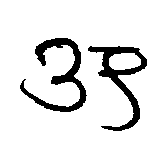
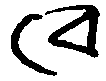
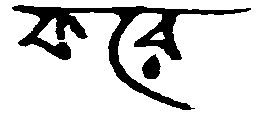
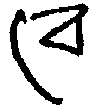
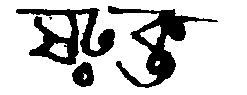
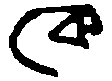
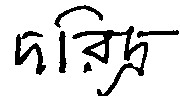
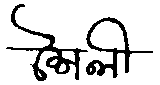
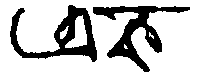
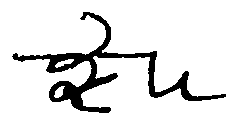
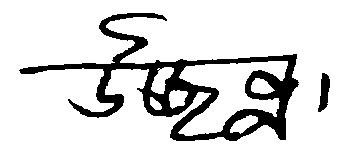
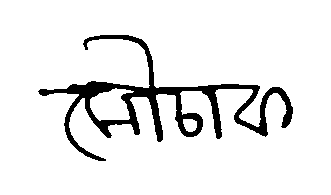
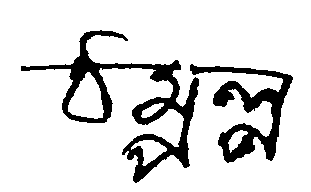
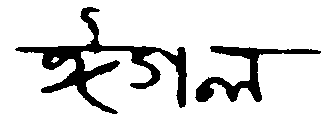
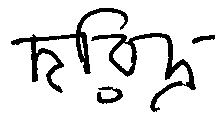
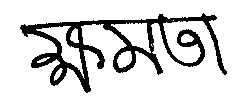
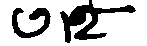
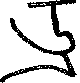

In [22]:
# Change PAGE to 2, 3, ... to inspect the next group of images.
PAGE = 1
IMAGES_PER_PAGE = 20

page_count = (len(word_images_200) + IMAGES_PER_PAGE - 1) // IMAGES_PER_PAGE
assert 1 <= PAGE <= page_count, f'Choose PAGE between 1 and {page_count}.'
start = (PAGE - 1) * IMAGES_PER_PAGE
page_images = word_images_200.iloc[start:start + IMAGES_PER_PAGE]

print(f'Page {PAGE}/{page_count}: image above, predicted whole word below.')
display(HTML(prediction_gallery(page_images)))


In [23]:
# Open one HTML file to inspect all 200 images and predictions together.
# This only renders saved outputs; it does not run either model again.
all_predictions_page = REPORT_200 / 'images_and_predictions.html'
document = (
    '<!doctype html><html><head><meta charset="utf-8">'
    '<title>Handwritten word predictions</title></head><body>'
    '<h1>Images and predicted words</h1>'
    '<p>Model outputs for visual inspection. Status does not indicate correctness.</p>'
    + prediction_gallery(word_images_200) + '</body></html>'
)
all_predictions_page.write_text(document, encoding='utf-8')
display(FileLink(str(all_predictions_page.relative_to(PROJECT_DIR))))


/Users/sakibsmacbookm5/Documents/Python work/research-project/SICIP - Assignment 4/reports/hybrid_word_recognition/test_200_words/images_and_predictions.html

In [24]:
# Optional: calculate accuracy only if independently checked labels already exist.
# This never asks you to type labels, and is disabled for visual inspection.
SHOW_ACCURACY = False

if SHOW_ACCURACY:
    _, metrics_200 = score_word_benchmark(REFERENCE_200, REPORT_200, count=200)
    if metrics_200['exact_word_accuracy'] is not None:
        print(f"Exact word accuracy: {metrics_200['exact_word_accuracy']:.2%}")
    else:
        print('Numerical accuracy requires reference words; the image gallery needs none.')
